In [1]:
import pandas as pd
import sqlite3

orders = pd.read_csv("store_orders.csv")
customers = pd.read_csv("store_customers.csv")

con = sqlite3.connect("store.db")

orders.to_sql("orders", con, if_exists="replace", index=False)
customers.to_sql("customers", con, if_exists="replace", index=False)

pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con)

,name
0,orders
1,customers


In [2]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [3]:
pd.read_sql("""
SELECT *
FROM orders
WHERE amount > 100
ORDER BY amount DESC
""", con)

,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
...,...,...,...,...,...,...
79,5107,38,shelf,furniture,110.31,2026-05-17
80,5046,13,shelf,furniture,108.47,2026-05-28
81,5009,14,chair,furniture,107.20,2026-05-24
82,5007,36,dock,electronics,103.77,2026-05-21


In [4]:
category_results = pd.read_sql("""
SELECT
    category,
    COUNT(*) AS n,
    AVG(amount) AS avg_amount
FROM orders
GROUP BY category
ORDER BY avg_amount DESC
""", con)

category_results

,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


Off the results, Electronics had the highest average order amount at around $190.57. This means customers spent more per order on electronics compared to the other categories.

In [5]:
city_results = pd.read_sql("""
SELECT
    c.city,
    SUM(o.amount) AS total_spend
FROM orders AS o
JOIN customers AS c
    ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY total_spend DESC
""", con)

city_results

,city,total_spend
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


In [6]:
row_audit = pd.read_sql("""
SELECT
    (SELECT COUNT(*) FROM orders) AS total_orders,
    (SELECT COUNT(*)
     FROM orders o
     JOIN customers c
     ON o.customer_id = c.customer_id) AS joined_orders
""", con)

row_audit

,total_orders,joined_orders
0,200,195


After joining the two tables, one thing I noticed was that five orders were missing from the results due to the fact that their customer IDs weren't in the customers table. Since an inner join only keeps rows with matching IDs, those five orders were left out.

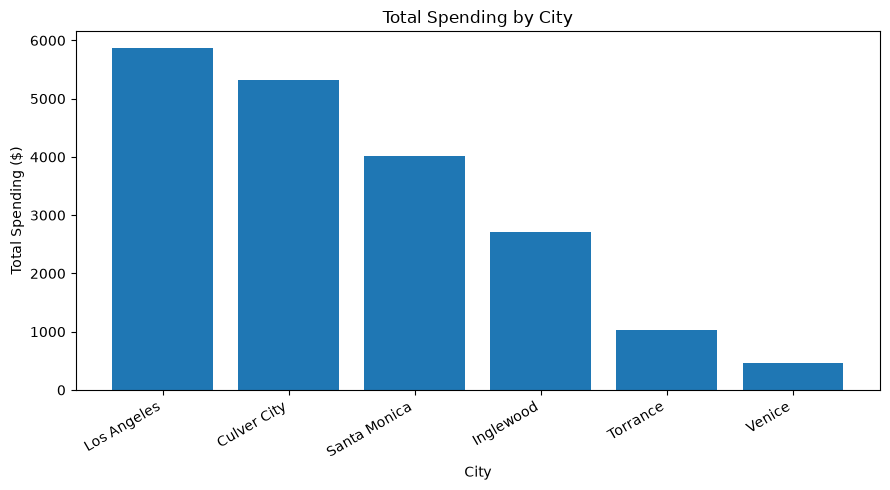

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(city_results["city"], city_results["total_spend"])

plt.title("Total Spending by City")
plt.xlabel("City")
plt.ylabel("Total Spending ($)")
plt.xticks(rotation=30, ha="right")
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()

My Business Question: Which product generated the most money in total sales?

In [8]:
product_results = pd.read_sql("""
SELECT
    product,
    SUM(amount) AS total_revenue
FROM orders
GROUP BY product
ORDER BY total_revenue DESC
""", con)

product_results

,product,total_revenue
0,headset,4902.30
1,dock,3357.14
2,monitor,3174.73
3,shelf,3030.45
4,chair,2589.93
5,desk,1107.19
6,pens,597.78
7,paper,526.55
8,planner,412.43
9,granola,258.56


After running my query, the result I got was that headsets made the most money overall, with around $4,902.30 in total sales. I found this interesting as it showed the headsets contribution to the stores revenue the most.

If I were to share the data publicily, would exclude customer names or any information that could identify them. Instead, what i would do is show the total spending by city so people could still understand the sales results without exposing sensitive customer info.

GitHub Repository
https://github.com/leonhong2007/cs82a-portfolio/tree/main/module6